In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
import re,string


In [2]:
df = pd.read_csv(r'IMDB_Dataset.csv')

In [3]:
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


<Axes: xlabel='sentiment', ylabel='count'>

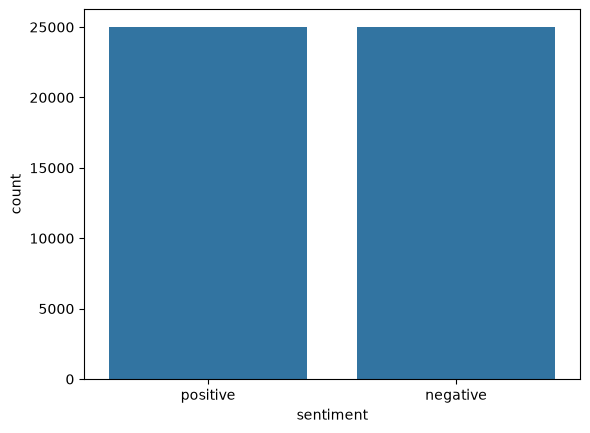

In [4]:
sns.countplot(data=df,x='sentiment')

In [6]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [7]:
def mapping(text):
    if text == 'positive':
        return 1
    else:
        return 0

In [9]:
df['sentiment']=df['sentiment'].apply(mapping)

In [10]:
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1
...,...,...
49995,I thought this movie did a down right good job...,1
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",0
49997,I am a Catholic taught in parochial elementary...,0
49998,I'm going to have to disagree with the previou...,0


In [16]:
_ss    = SnowballStemmer('english')
_STOP  = set(stopwords.words('english'))
_URL   = re.compile(r'https?://\S+|www\.\S+')
_HTML  = re.compile(r'<.*?>', re.DOTALL)
_BRACK = re.compile(r'\[.*?\]', re.DOTALL)
_PUNCT = re.compile(f"[{re.escape(string.punctuation.replace(chr(39), ''))}]")  # keeps apostrophe
_DIGIT = re.compile(r'\w*\d\w*')

In [ ]:
def wordopt(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = _URL.sub(' ', text)
    text = _BRACK.sub(' ', text)
    text = _PUNCT.sub(' ', text)
    text = _DIGIT.sub(' ', text)
    words = [w for w in text.split() if w not in _STOP]       # "don't" matched before apostrophe is stripped
    words = [_ss.stem(w.replace("'", "")) for w in words]
    return ' '.join(w for w in words if w)

In [19]:
df['review'] = df['review'].apply(wordopt)

In [20]:
df

,review,sentiment
0,one review mention watch oz episod hook right ...,1
1,wonder littl product film techniqu unassum old...,1
2,thought wonder way spend time hot summer weeke...,1
3,basic there famili littl boy jake think there ...,0
4,petter mattei love time money visual stun film...,1
...,...,...
49995,thought movi right good job creativ origin fir...,1
49996,bad plot bad dialogu bad act idiot direct anno...,0
49997,cathol taught parochi elementari school nun ta...,0
49998,go disagre previous comment side maltin one se...,0


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
tfidf=TfidfVectorizer(max_features=5000)
X=tfidf.fit_transform(df['review']).toarray()


In [ ]:
np.set_printoptions(edgeitems=30, linewidth=100000, 
    formatter=dict(float=lambda x: "%.3g" % x))

In [29]:
X

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0.0941, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.0631, 0, 0, 0, 0, 0, 0, 0, 0, 0.0782, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.222, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.0979, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      

In [30]:
tfidf.vocabulary_

{'one': np.int64(3115),
 'review': np.int64(3697),
 'mention': np.int64(2806),
 'watch': np.int64(4845),
 'oz': np.int64(3172),
 'episod': np.int64(1495),
 'hook': np.int64(2139),
 'right': np.int64(3721),
 'exact': np.int64(1543),
 'happen': np.int64(2021),
 'first': np.int64(1693),
 'thing': np.int64(4483),
 'struck': np.int64(4287),
 'brutal': np.int64(567),
 'scene': np.int64(3856),
 'violenc': np.int64(4785),
 'set': np.int64(3940),
 'word': np.int64(4943),
 'go': np.int64(1906),
 'trust': np.int64(4621),
 'show': np.int64(3997),
 'faint': np.int64(1604),
 'heart': np.int64(2057),
 'pull': np.int64(3488),
 'punch': np.int64(3492),
 'regard': np.int64(3612),
 'drug': np.int64(1345),
 'sex': np.int64(3946),
 'hardcor': np.int64(2027),
 'classic': np.int64(795),
 'use': np.int64(4724),
 'call': np.int64(614),
 'given': np.int64(1889),
 'secur': np.int64(3897),
 'state': np.int64(4223),
 'focus': np.int64(1728),
 'main': np.int64(2710),
 'citi': np.int64(785),
 'experiment': np.int64(

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 781.4 KB


In [ ]:

y=df['sentiment']

In [42]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [43]:
def Model_train(x_train,x_test,y_train,y_test):
    models={
    'LR':LogisticRegression(),
    'RF':RandomForestClassifier(n_estimators=50,n_jobs=-1,max_depth=30),
    'XGB':XGBClassifier(n_estimators=50,n_jobs=-1),
    
    }
    result=[]
    for name,model in models.items():
        model.fit(x_train,y_train)
        y_pred = model.predict(x_test)
        score = accuracy_score(y_test,y_pred)
        print(score)


In [44]:
Model_train(x_train,x_test,y_train,y_test)

NameError: name 'accuracy_score' is not defined